# 01 — Exploratory Data Analysis
**Project:** From Tags to Sound: explainable cold-start recommendation for new artists

This notebook only *explores and checks* the data. No models yet.

| Section | Question it answers | Links to |
|---|---|---|
| 1 | What is in the raw HetRec 2011 dataset? | data |
| 2 | How skewed are listening counts? Why log1p? | slide 5 |
| 3 | What does the ≥5-listener filter remove? | slide 5 |
| 4 | Are the tags usable? Do 3 tags make artists look identical? | RQ2, slide 3 |
| 5 | How well do names match on Deezer? Which genres? | slide 4, RQ3 |
| 6 | What do the 38 audio numbers look like? | RQ2, slide 5 |
| 7 | Head vs tail artists | RQ1 |
| 8 | Final summary | — |

Run `src/clean.py`, `src/collect_deezer.py` and `src/build_profiles.py` first.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from load_data import load_all
from config import PROCESSED_DIR, FIG_DIR

# Validated palette (light mode): blue = main series, orange = comparison, aqua = 3rd
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#b5b3ab"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d6d4cc", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110,
})
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 160)

## 1. Raw dataset overview (HetRec 2011, Last.fm)

In [2]:
raw = load_all()
overview = pd.DataFrame({
    name: {"rows": len(df), "columns": ", ".join(df.columns),
           "missing values": int(df.isna().sum().sum()),
           "duplicate rows": int(df.duplicated().sum())}
    for name, df in raw.items()}).T
overview

,rows,columns,missing values,duplicate rows
artists,17632,"artistID, name, url, pictureURL",444,0
tags,11946,"tagID, tagValue",0,0
user_artists,92834,"userID, artistID, weight",0,0
user_taggedartists,186479,"userID, artistID, tagID, day, month, year",0,0
user_friends,25434,"userID, friendID",0,0


In [3]:
ua = raw["user_artists"]
n_users, n_artists = ua.userID.nunique(), ua.artistID.nunique()
print(f"Users: {n_users:,}   Artists listened to: {n_artists:,}   Artists in artists.dat: {len(raw['artists']):,}")
print(f"User-artist pairs: {len(ua):,}")
print(f"Sparsity: {1 - len(ua) / (n_users * n_artists):.4%} of the user x artist matrix is empty")
print(f"Artists per user: min {ua.groupby('userID').size().min()}, median {ua.groupby('userID').size().median():.0f}, max {ua.groupby('userID').size().max()}")
print(f"Play count (weight): min {ua.weight.min()}, median {ua.weight.median():.0f}, max {ua.weight.max():,}")

Users: 1,892   Artists listened to: 17,632   Artists in artists.dat: 17,632
User-artist pairs: 92,834
Sparsity: 99.7217% of the user x artist matrix is empty
Artists per user: min 1, median 50, max 50
Play count (weight): min 1, median 260, max 352,698


Each user has **at most 50 artists** (their top 50 on Last.fm). The matrix is >99% empty,
which is normal for recommender data.

## 2. Play counts are extremely skewed → use log1p

count     92834.0
mean        745.2
std        3751.3
min           1.0
25%         107.0
50%         260.0
75%         614.0
90%        1387.0
99%        7228.0
max      352698.0


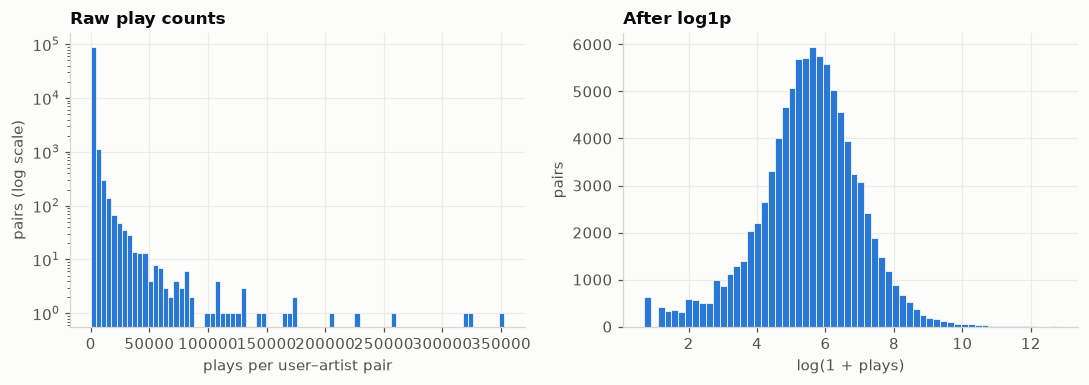

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(ua.weight, bins=80, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
axes[0].set_yscale("log"); axes[0].set_title("Raw play counts")
axes[0].set_xlabel("plays per user–artist pair"); axes[0].set_ylabel("pairs (log scale)")
axes[1].hist(np.log1p(ua.weight), bins=60, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
axes[1].set_title("After log1p"); axes[1].set_xlabel("log(1 + plays)"); axes[1].set_ylabel("pairs")
save(fig, "02_playcount_log1p")
print(ua.weight.describe(percentiles=[.25,.5,.75,.9,.99]).round(1).to_string())

Raw counts go from 1 to 352,698. After `log1p` they sit between about 0.7 and 12.8,
a scale that fits alongside the audio numbers.

Artists with only 1 listener: 10,679 (60.6%)


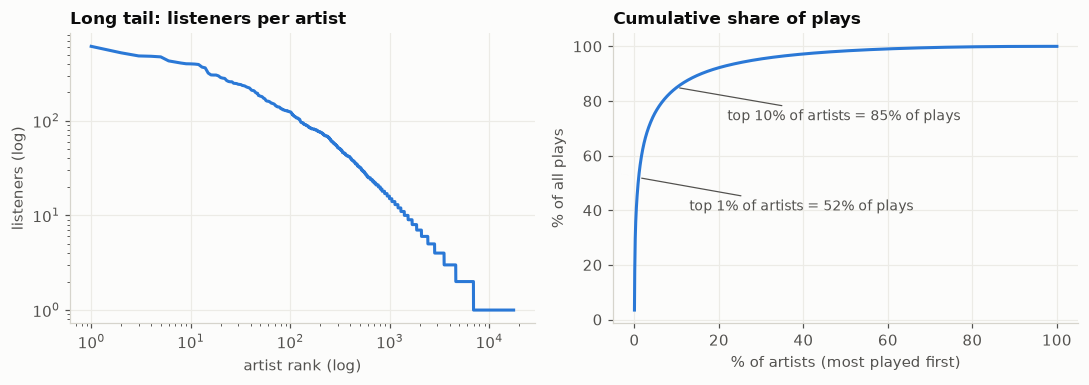

In [5]:
listeners = ua.groupby("artistID").userID.nunique().sort_values(ascending=False)
plays = ua.groupby("artistID").weight.sum().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(np.arange(1, len(listeners)+1), listeners.values, color=BLUE, lw=2)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_title("Long tail: listeners per artist"); axes[0].set_xlabel("artist rank (log)"); axes[0].set_ylabel("listeners (log)")
cum = plays.cumsum() / plays.sum()
axes[1].plot(np.arange(1, len(cum)+1) / len(cum) * 100, cum.values * 100, color=BLUE, lw=2)
for p in (1, 10):
    v = cum.iloc[int(len(cum) * p / 100) - 1] * 100
    axes[1].annotate(f"top {p}% of artists = {v:.0f}% of plays", (p, v), xytext=(p + 12, v - 12),
                     color=INK2, fontsize=9, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
axes[1].set_title("Cumulative share of plays"); axes[1].set_xlabel("% of artists (most played first)"); axes[1].set_ylabel("% of all plays")
save(fig, "02_long_tail")
print(f"Artists with only 1 listener: {(listeners == 1).sum():,} ({(listeners == 1).mean():.1%})")

This is the long tail. Most artists have one or two listeners, and a few artists get most of the plays.
Collaborative filtering struggles with tail artists, and a new artist has **zero** listeners.

## 3. Effect of the ≥ 5 listener filter

In [6]:
rows = []
for k in [1, 2, 3, 5, 10, 20]:
    keep = listeners[listeners >= k].index
    rows.append({"min listeners": k, "artists kept": len(keep),
                 "% artists removed": round(100 * (1 - len(keep) / len(listeners)), 1),
                 "% plays kept": round(100 * plays.loc[keep].sum() / plays.sum(), 1),
                 "% pairs kept": round(100 * ua.artistID.isin(keep).mean(), 1)})
filt = pd.DataFrame(rows); filt

,min listeners,artists kept,% artists removed,% plays kept,% pairs kept
0,1,17632,0.0,100.0,100.0
1,2,6953,60.6,94.4,88.5
2,3,4614,73.8,91.3,83.5
3,5,2828,84.0,87.1,76.9
4,10,1530,91.3,80.9,67.9
5,20,804,95.4,72.8,57.3


In [7]:
inter = pd.read_csv(PROCESSED_DIR / "interactions.csv")
print(f"After cleaning: {inter.userID.nunique():,} users, {inter.artistID.nunique():,} artists, {len(inter):,} interactions")
print(f"Users who lost all their artists: {n_users - inter.userID.nunique()}")
per_user = inter.groupby("userID").size()
print(f"Artists per user after filter: min {per_user.min()}, median {per_user.median():.0f}, max {per_user.max()}")

After cleaning: 1,881 users, 2,828 artists, 71,426 interactions
Users who lost all their artists: 11
Artists per user after filter: min 1, median 41, max 50


Threshold 5 removes **84% of artists but keeps 87% of plays**, as on slide 5. The removed artists
are almost all one-listener artists, and they carry too little signal to evaluate on.

## 4. Tags: raw vs clean, and the *identical profile* problem

In [8]:
from clean import normalize_tag, NON_DESCRIPTIVE_TAGS
tags_raw = raw["user_taggedartists"].merge(raw["tags"], on="tagID")
at = pd.read_csv(PROCESSED_DIR / "artist_tags.csv")
print(f"Raw distinct tags used: {tags_raw.tagValue.nunique():,}  ->  clean distinct tags: {at.tag.nunique():,}")
print("Examples of merged variants:")
for t in ["Hip-Hop", "hip hop", "hiphop", "Female Vocalist", "synthpop", "R&B", "Post-Punk"]:
    print(f"   {t!r:20} -> {normalize_tag(t)!r}")
removed = tags_raw[tags_raw.tagValue.map(normalize_tag).isin(NON_DESCRIPTIVE_TAGS)]
print(f"Tag applications removed as opinion / non-descriptive: {len(removed):,} ({len(removed)/len(tags_raw):.1%})")
print(removed.tagValue.str.lower().value_counts().head(8).to_string())

Raw distinct tags used: 9,749  ->  clean distinct tags: 6,392
Examples of merged variants:
   'Hip-Hop'            -> 'hip hop'
   'hip hop'            -> 'hip hop'
   'hiphop'             -> 'hip hop'
   'Female Vocalist'    -> 'female vocalists'
   'synthpop'           -> 'synth pop'
   'R&B'                -> 'r and b'
   'Post-Punk'          -> 'post punk'


Tag applications removed as opinion / non-descriptive: 7,258 (3.9%)
tagValue
seen live               1439
awesome                  625
love                     620
cover                    583
amazing                  539
favorites                448
<3                       355
love at first listen     349


Artists with >=1 / >=3 / >=5 clean tags: 99.6% / 96.8% / 90.7%


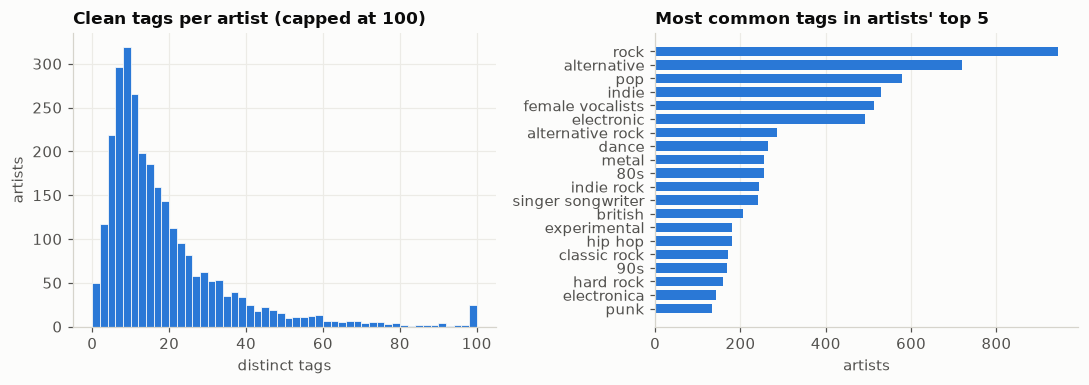

In [9]:
art = pd.read_csv(PROCESSED_DIR / "artists_filtered.csv")
n_tags = at.groupby("artistID").size().reindex(art.artistID, fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(n_tags.clip(upper=100), bins=50, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
axes[0].set_title("Clean tags per artist (capped at 100)"); axes[0].set_xlabel("distinct tags"); axes[0].set_ylabel("artists")
top = at[at["rank"] <= 5].tag.value_counts().head(20)[::-1]
axes[1].barh(top.index, top.values, color=BLUE, height=0.7)
axes[1].set_title("Most common tags in artists' top 5"); axes[1].set_xlabel("artists"); axes[1].grid(axis="y", visible=False)
save(fig, "04_tags")
print(f"Artists with >=1 / >=3 / >=5 clean tags: {(n_tags>=1).mean():.1%} / {(n_tags>=3).mean():.1%} / {(n_tags>=5).mean():.1%}")

### Why audio was added (slide 3)
If two artists have the **same set of top-k tags**, a tag-only model sees them as the same artist.
Below we count how often that happens for k = 1, 3, 5.

In [10]:
topk = pd.read_csv(PROCESSED_DIR / "artist_tags_topk.csv")
rows = []
for k in [1, 3, 5]:
    sets = topk[f"tags_top{k}"].dropna().map(lambda s: "|".join(sorted(s.split("|"))))
    counts = sets.map(sets.value_counts())
    rows.append({"k tags": k, "unique tag profiles": sets.nunique(),
                 "artists sharing their exact profile": int((counts > 1).sum()),
                 "% sharing": round(100 * (counts > 1).mean(), 1),
                 "biggest identical group": int(counts.max())})
ties = pd.DataFrame(rows); display(ties)
s3 = topk.tags_top3.dropna().map(lambda s: "|".join(sorted(s.split("|"))))
print("Most common identical top-3 profiles:")
print(s3.value_counts().head(8).to_string())

,k tags,unique tag profiles,artists sharing their exact profile,% sharing,biggest identical group
0,1,199,2753,97.8,224
1,3,1568,1638,58.2,62
2,5,2394,632,22.4,33


Most common identical top-3 profiles:
tags_top3
alternative|alternative rock|rock    62
alternative|indie|indie rock         36
alternative|indie|rock               33
dance|female vocalists|pop           31
british|indie|indie rock             23
female vocalists|pop|r and b         19
classic rock|hard rock|rock          18
indie|indie rock|rock                16


With only 1 or 3 tags, many artists have **exactly the same tag profile**, so a tag-only model
cannot rank them against each other. Audio is different for every artist, so it breaks these ties.
This is the evidence behind the change on slide 3.

## 5. Deezer: name matching and genres

In [11]:
dz = pd.read_csv(PROCESSED_DIR / "deezer_artists.csv")
prof = pd.read_csv(PROCESSED_DIR / "artist_profiles.csv")
status = dz.status.value_counts()
print(status.to_string()); print(f"\nArtists queried: {len(dz):,}")
print(f"Accepted name match (score >= 0.85): {dz.status.isin(['ok','no_preview','audio_error']).mean():.1%}")
print(f"Exact normalised name match (score = 1.0): {(dz.match_score == 1).mean():.1%}")

status
ok              2713
no_preview        73
low_match         33
not_found          6
invalid_name       3

Artists queried: 2,828
Accepted name match (score >= 0.85): 98.5%
Exact normalised name match (score = 1.0): 97.8%


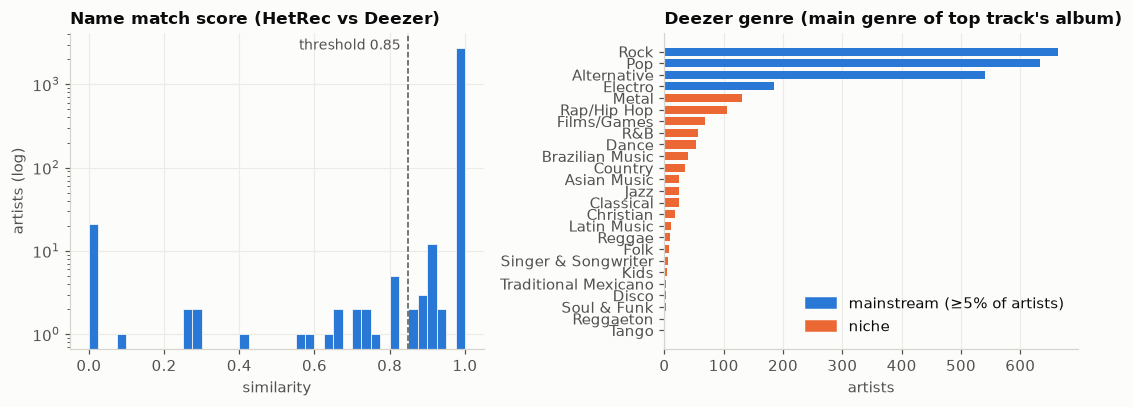

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].hist(dz.match_score.dropna(), bins=40, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
axes[0].axvline(0.85, color=INK2, lw=1, ls="--"); axes[0].text(0.84, axes[0].get_ylim()[1]*0.9, "threshold 0.85 ", ha="right", color=INK2, fontsize=9)
axes[0].set_yscale("log"); axes[0].set_title("Name match score (HetRec vs Deezer)"); axes[0].set_xlabel("similarity"); axes[0].set_ylabel("artists (log)")
g = prof.genre.value_counts()
colors = [BLUE if prof.loc[prof.genre == x, "genre_group"].iloc[0] == "mainstream" else ORANGE for x in g.index]
axes[1].barh(g.index[::-1], g.values[::-1], color=colors[::-1], height=0.7)
axes[1].set_title("Deezer genre (main genre of top track's album)"); axes[1].set_xlabel("artists"); axes[1].grid(axis="y", visible=False)
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color=BLUE, label="mainstream (≥5% of artists)"), Patch(color=ORANGE, label="niche")], frameon=False, loc="lower right")
save(fig, "05_deezer_match_genre")

In [13]:
print("Rejected / doubtful matches (check by hand):")
display(dz[dz.status == "low_match"].sort_values("match_score", ascending=False)[["name", "deezer_name", "match_score"]].head(15))
print("Accepted but not exact (fuzzy) matches:")
display(dz[(dz.match_score < 1) & (dz.match_score >= 0.85)][["name", "deezer_name", "match_score"]].head(15))

Rejected / doubtful matches (check by hand):


,name,deezer_name,match_score
2795,Karen O and the Kids,Karen & Kids,0.824
2739,30 Seconds to Mars,Thirty Seconds to Mars,0.800
2762,Dethklok,De Klok,0.800
2818,Dima Bilan,Die Bilanz,0.800
2791,Auf der Maur,Fides Auf der Maur,0.800
2799,Chylińska,Julia Chylińska,0.750
2757,Godspeed You! Black Emperor,Godspeed You! Black Boo Dudes,0.741
2798,Каста,Каскад,0.727
2761,Danny,D a n n y,0.714
2780,Enrique Bunbury,Shuarma con Enrique Bunbury,0.714


Accepted but not exact (fuzzy) matches:


,name,deezer_name,match_score
2741,Martin L. Gore,Martin Gore,0.917
2742,Bob Marley,Bob Marley & The Wailers,0.900
2743,The Jimi Hendrix Experience,Jimi Hendrix,0.900
2744,nevershoutnever!,Never Shout Never,0.938
2750,Dixie Chicks,Dixie Chicks & Me,0.900
2753,Cat Stevens,Cat Stevens (Karaoke),0.900
2754,O Teatro Mágico,Teatro Mágico,0.929
2755,植松伸夫,植松 伸夫,0.889
2759,HEVO84,Hevo 84,0.923
2782,Death in June,Death In June & Boyd Rice,0.900


**Things to note for the report**
- Deezer artists have no genre field, so the genre comes from the album of the artist's top track.
  That is a proxy and it can be wrong for crossover artists.
- Deezer's *top* track is based on today's popularity, not 2011. Good enough to describe the
  artist's sound, but it is a limitation.
- Some short or common names (for example "Air" or "Live") can match the wrong artist even with a
  high score. The table above helps find them.

## 6. Audio features (38 numbers per artist)

From each 30-second preview, `librosa` computes:
- **13 MFCC means**: the overall timbre or "colour" of the sound
- **13 MFCC standard deviations**: how much the timbre changes during the clip
- **12 chroma means**: how much energy falls on each of the 12 pitch classes (C, C#, … B), between 0 and 1

In [14]:
from collect_deezer import FEATURE_NAMES
A = prof.loc[prof.has_audio, ["artistID", "name", "genre", "genre_group"] + FEATURE_NAMES].reset_index(drop=True)
print(f"Artists with audio: {len(A):,} / {len(prof):,}")
desc = A[FEATURE_NAMES].describe().T[["mean", "std", "min", "max"]].round(3)
display(desc)
print(f"Feature scale ranges: smallest std = {desc['std'].min():.3f}, largest std = {desc['std'].max():.1f}")
print("-> very different scales: StandardScaler is needed (fit on train split only).")

Artists with audio: 2,713 / 2,828


,mean,std,min,max
mfcc1_mean,-66.259,84.191,-548.919,74.693
mfcc2_mean,90.144,28.034,18.091,225.010
mfcc3_mean,-1.027,17.209,-76.897,94.031
mfcc4_mean,27.206,11.283,-38.952,94.170
mfcc5_mean,6.056,7.512,-34.811,48.763
mfcc6_mean,8.745,7.088,-27.476,36.002
mfcc7_mean,1.082,5.893,-28.006,34.031
mfcc8_mean,5.987,6.159,-32.594,24.339
mfcc9_mean,-1.354,5.623,-33.318,18.734
mfcc10_mean,4.485,5.132,-26.300,19.738


Feature scale ranges: smallest std = 0.113, largest std = 84.2
-> very different scales: StandardScaler is needed (fit on train split only).


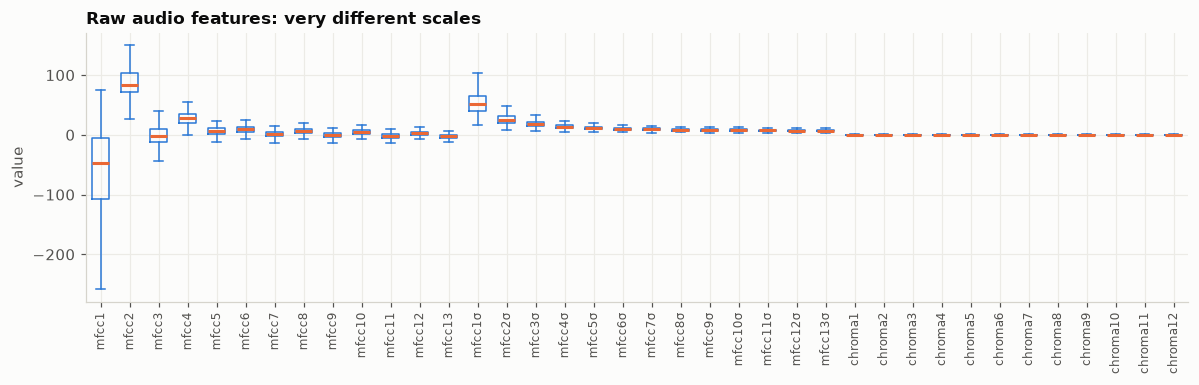

In [15]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.boxplot([A[c] for c in FEATURE_NAMES], showfliers=False, widths=0.6,
           medianprops=dict(color=ORANGE, lw=2), boxprops=dict(color=BLUE), whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
ax.set_xticks(range(1, 39)); ax.set_xticklabels([c.replace("_mean","").replace("_std","σ") for c in FEATURE_NAMES], rotation=90, fontsize=8)
ax.set_title("Raw audio features: very different scales"); ax.set_ylabel("value")
save(fig, "06_audio_scales")

Most correlated feature pairs:
mfcc10_std  mfcc11_std    0.80
mfcc12_std  mfcc13_std    0.80
mfcc7_std   mfcc8_std     0.79
mfcc9_std   mfcc10_std    0.79
mfcc8_std   mfcc9_std     0.79
mfcc6_std   mfcc8_std     0.79
mfcc11_std  mfcc12_std    0.79
            mfcc13_std    0.77


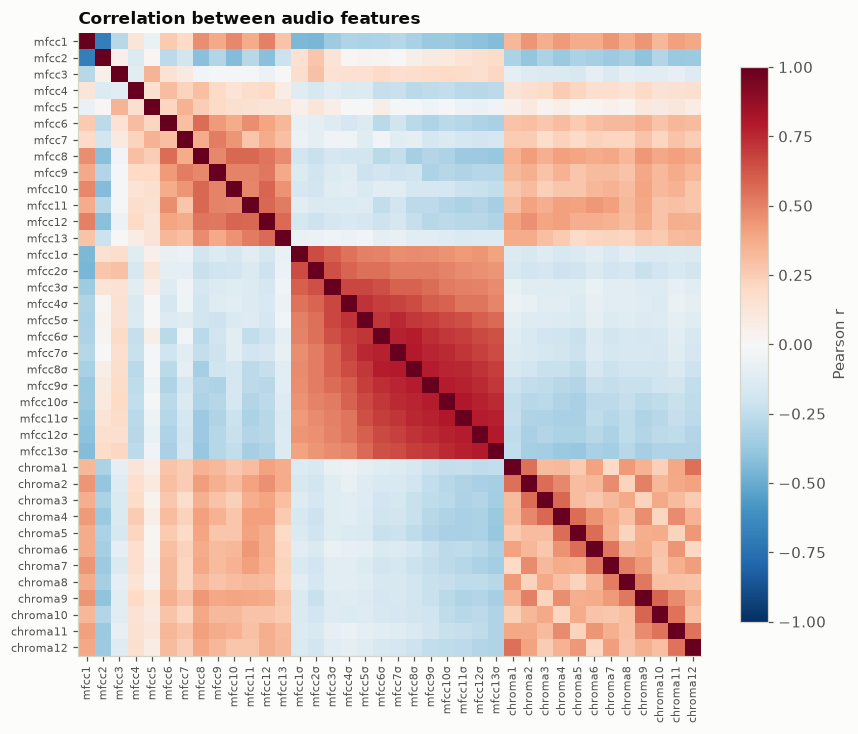

In [16]:
corr = A[FEATURE_NAMES].corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(38)); ax.set_yticks(range(38))
short = [c.replace("_mean","").replace("_std","σ") for c in FEATURE_NAMES]
ax.set_xticklabels(short, rotation=90, fontsize=7); ax.set_yticklabels(short, fontsize=7); ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Correlation between audio features")
save(fig, "06_audio_corr")
high = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().abs().sort_values(ascending=False)
print("Most correlated feature pairs:"); print(high.head(8).round(2).to_string())

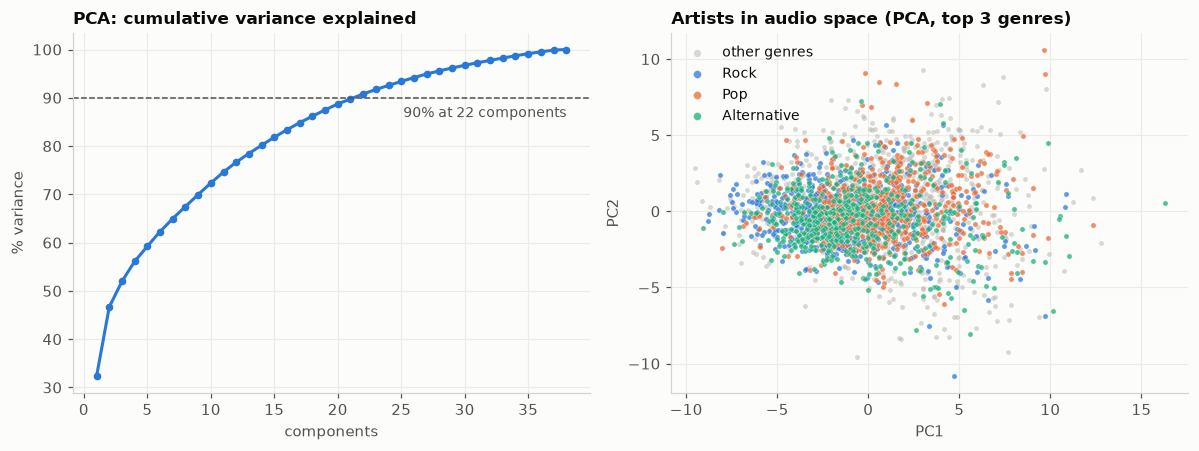

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
Z = StandardScaler().fit_transform(A[FEATURE_NAMES])   # for visualisation only
pca = PCA().fit(Z); P = pca.transform(Z)[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(range(1, 39), np.cumsum(pca.explained_variance_ratio_) * 100, color=BLUE, lw=2, marker="o", ms=4)
axes[0].set_title("PCA: cumulative variance explained"); axes[0].set_xlabel("components"); axes[0].set_ylabel("% variance")
n90 = int(np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.9)) + 1
axes[0].axhline(90, color=INK2, lw=1, ls="--"); axes[0].text(38, 86, f"90% at {n90} components", ha="right", color=INK2, fontsize=9)
top3 = A.genre.value_counts().index[:3]
cmap = dict(zip(top3, [BLUE, ORANGE, AQUA]))
other = ~A.genre.isin(top3)
axes[1].scatter(P[other, 0], P[other, 1], s=10, color=GRAY, alpha=0.5, label="other genres", linewidths=0)
for gname, col in cmap.items():
    m = (A.genre == gname).values
    axes[1].scatter(P[m, 0], P[m, 1], s=12, color=col, alpha=0.75, label=gname, edgecolors="#fcfcfb", linewidths=0.3)
axes[1].set_title("Artists in audio space (PCA, top 3 genres)"); axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].legend(frameon=False, fontsize=9, markerscale=1.5)
save(fig, "06_audio_pca")

In [18]:
# Does audio separate genres?  Simple check: silhouette score per genre group
from sklearn.metrics import silhouette_samples
valid = A.genre.notna() & A.genre.map(A.genre.value_counts()).ge(20)
sil = pd.Series(silhouette_samples(Z[valid], A.genre[valid]), index=A.index[valid])
by_genre = sil.groupby(A.genre[valid]).agg(["mean", "size"]).sort_values("mean", ascending=False).round(3)
by_genre["group"] = by_genre.index.map(A.drop_duplicates("genre").set_index("genre").genre_group)
by_genre

,mean,size,group
genre,,,
Country,0.102,34,niche
Metal,0.052,130,niche
Rap/Hip Hop,-0.021,106,niche
R&B,-0.057,57,niche
Jazz,-0.083,25,niche
Classical,-0.088,24,niche
Asian Music,-0.092,25,niche
Brazilian Music,-0.094,40,niche
Rock,-0.098,664,mainstream


Silhouette above 0 means the genre's artists sit closer to each other in audio space than to
other genres. Genres with a clear sound (often metal or electronic) should score higher, which is the
idea behind **RQ3**. This is only a first check. The real test comes in the evaluation.

## 7. Head vs tail artists (RQ1 set-up)

In [19]:
summary = prof.groupby("popularity_bucket").agg(
    artists=("artistID", "size"), median_listeners=("n_listeners", "median"),
    share_of_plays=("total_plays", "sum"),
    pct_with_5_tags=("n_clean_tags", lambda s: round(100 * (s >= 5).mean(), 1)),
    pct_with_genre=("genre", lambda s: round(100 * s.notna().mean(), 1)),
    pct_with_audio=("has_audio", lambda s: round(100 * s.mean(), 1)))
summary["share_of_plays"] = (100 * summary.share_of_plays / summary.share_of_plays.sum()).round(1)
summary

,artists,median_listeners,share_of_plays,pct_with_5_tags,pct_with_genre,pct_with_audio
popularity_bucket,,,,,,
head,571,56.0,77.6,100.0,97.0,97.9
tail,2257,8.0,22.4,88.4,92.9,95.4


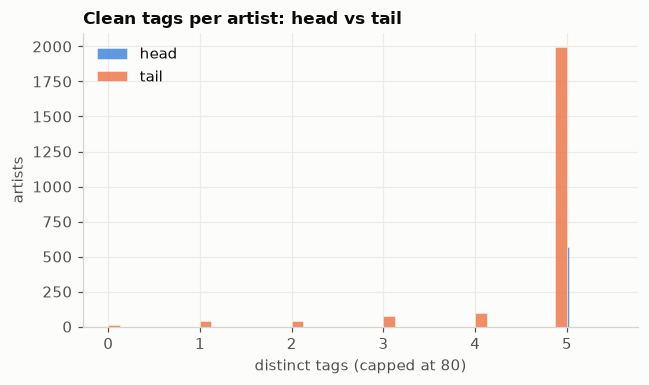

In [20]:
fig, ax = plt.subplots(figsize=(6, 3.6))
for b, col in [("head", BLUE), ("tail", ORANGE)]:
    ax.hist(prof.loc[prof.popularity_bucket == b, "n_clean_tags"].clip(upper=80), bins=40, alpha=0.75, color=col, label=b, edgecolor="#fcfcfb", linewidth=0.4)
ax.set_title("Clean tags per artist: head vs tail"); ax.set_xlabel("distinct tags (capped at 80)"); ax.set_ylabel("artists"); ax.legend(frameon=False)
save(fig, "07_head_tail_tags")

Tail artists have far fewer tags than head artists. Since new artists look like tail artists, testing
with only **1, 3 or 5 tags** is realistic. It also explains why audio matters most where tags are thin.

## 8. Final summary

In [21]:
complete = (prof.n_clean_tags > 0) & prof.genre.notna() & prof.has_audio
final = pd.Series({
    "Users (after filter)": f"{inter.userID.nunique():,}",
    "Artists (after filter)": f"{len(prof):,}",
    "Interactions": f"{len(inter):,}",
    "Artists with ≥1 tag": f"{(prof.n_clean_tags > 0).mean():.1%}",
    "Artists with 5 tags": f"{(prof.n_clean_tags >= 5).mean():.1%}",
    "Artists with Deezer genre": f"{prof.genre.notna().mean():.1%}",
    "Artists with audio (38 features)": f"{prof.has_audio.mean():.1%}",
    "Complete profiles (tags + genre + audio)": f"{complete.sum():,} ({complete.mean():.1%})",
    "Mainstream / niche artists": f"{(prof.genre_group=='mainstream').sum():,} / {(prof.genre_group=='niche').sum():,}",
}, name="value").to_frame()
final.to_csv(ROOT / "reports" / "eda_summary_table.csv")
final

,value
Users (after filter),"1,881"
Artists (after filter),"2,828"
Interactions,"71,426"
Artists with ≥1 tag,99.6%
Artists with 5 tags,90.7%
Artists with Deezer genre,93.7%
Artists with audio (38 features),95.9%
Complete profiles (tags + genre + audio),"2,640 (93.4%)"
Mainstream / niche artists,"2,022 / 628"


### Next steps (modelling, not part of this notebook)
1. **Cold-start split:** hold out a set of artists completely. Their interactions are hidden, and only
   their profile (tags, genre, audio) is visible.
2. Fit `StandardScaler` on the training artists' audio only.
3. Baselines: popularity, and CF (for example ALS or BPR) on warm artists.
4. Content models: tags only (k = 1/3/5), audio only, tags + audio. Compare accuracy
   (Recall@K, NDCG@K) and exposure (coverage of new artists) → RQ1/RQ2.
5. Break results down by mainstream vs niche genre → RQ3.